**Шаг 1 - Подключение библиотек**

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = '/content/drive/MyDrive/stzlr4'
raw_dir = Path(f'{base}/data')
results_dir = Path(f'{base}/results4')
results_dir.mkdir(parents=True, exist_ok=True)

print('OpenCV версия:', cv2.__version__)
print('Папка с исходными изображениями:', raw_dir)

OpenCV версия: 5.0.0
Папка с исходными изображениями: \content\drive\MyDrive\stzlr4\data


**Шаг 2 - Загрузка изображений**

Загружаем: LR44.jpg
Размер: 980 x 980 | Каналы: 3 | Тип: uint8


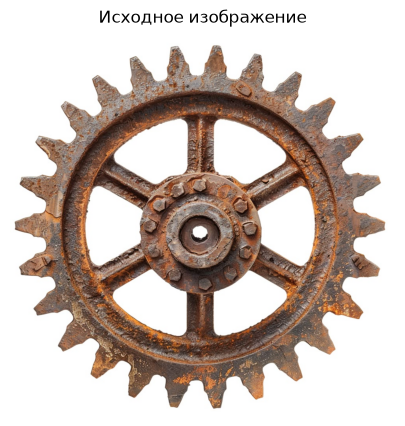

In [12]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Первое изображение в корне 
# img_path = next(
#     (p for p in sorted(Path('.').iterdir())
#      if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp'}),
#     None
# )
img_path = "LR44.jpg"
if img_path is None:
    raise FileNotFoundError('В корне нет изображений')

img = cv2.imread(str(img_path))
if img is None:
    raise FileNotFoundError(f'Не удалось прочитать: {img_path}')

h, w = img.shape[:2]
print(f'Загружаем: {img_path}')
print(f'Размер: {w} x {h} | Каналы: {img.shape[2]} | Тип: {img.dtype}')

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Исходное изображение')
plt.axis('off')
plt.show()

**Шаг 3 - Выделение границ методом Кенни**

C:\Users\kamil\AppData\Local\Temp\ipykernel_11764\3678137274.py:5: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(gray.ravel(), 256, [0, 256])


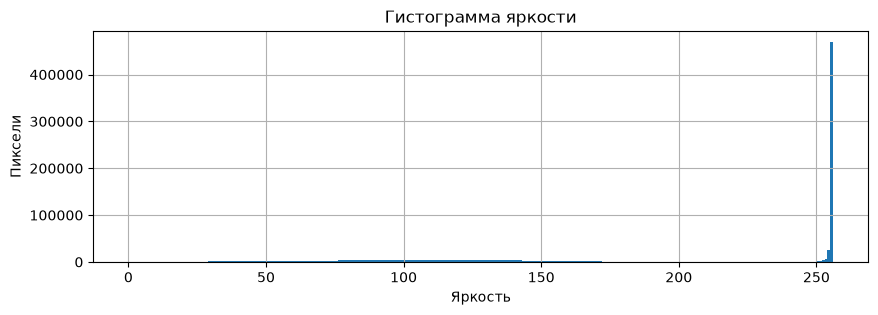

Средняя яркость: 184.41793627655144
СКО: 79.69976013872335
Min: 2 Max: 255


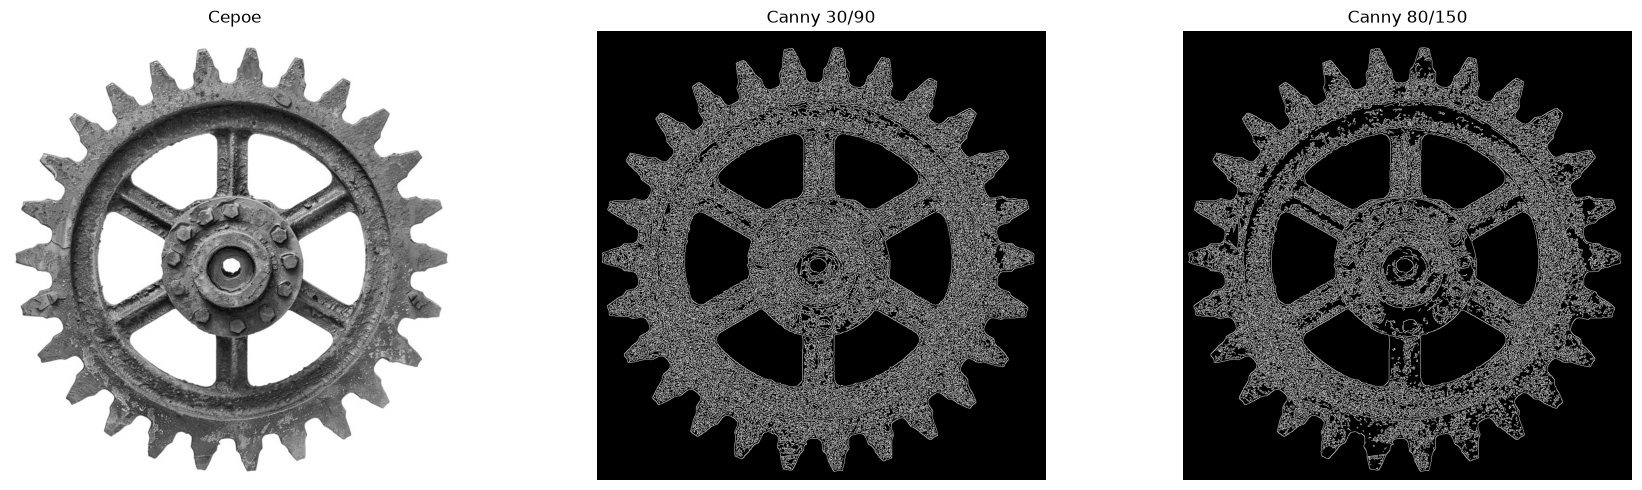

In [13]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Проверим гистограмму яркости
plt.figure(figsize=(10, 3))
plt.hist(gray.ravel(), 256, [0, 256])
plt.xlabel('Яркость')
plt.ylabel('Пиксели')
plt.title('Гистограмма яркости')
plt.grid(True)
plt.show()

print('Средняя яркость:', gray.mean())
print('СКО:', gray.std())
print('Min:', gray.min(), 'Max:', gray.max())

# Детектор Кэнни — два набора порогов
edges1 = cv2.Canny(gray, 30, 90)
edges2 = cv2.Canny(gray, 80, 150)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(gray, cmap='gray'); axes[0].set_title('Серое'); axes[0].axis('off')
axes[1].imshow(edges1, cmap='gray'); axes[1].set_title('Canny 30/90'); axes[1].axis('off')
axes[2].imshow(edges2, cmap='gray'); axes[2].set_title('Canny 80/150'); axes[2].axis('off')
plt.tight_layout()
plt.show()

**Шаг 4 - Поиск и анализ контура**

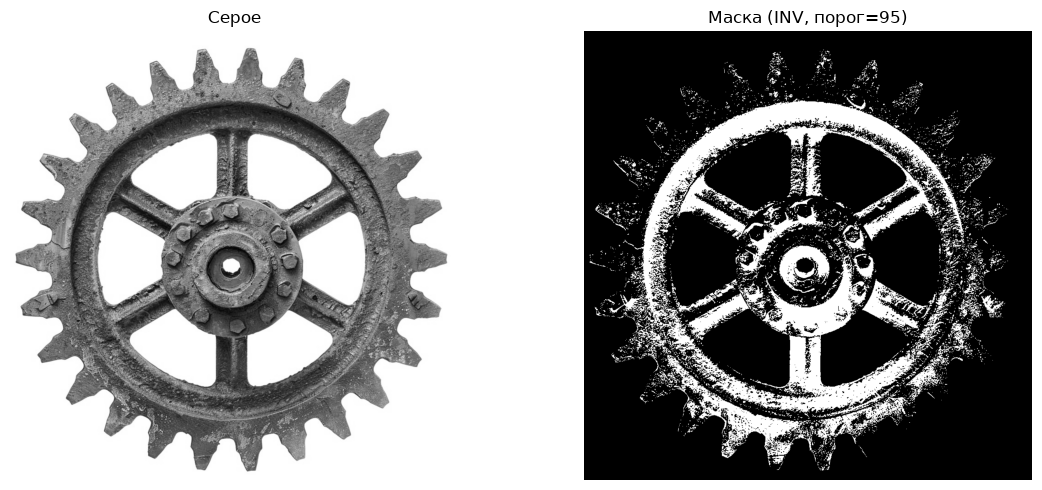

Найдено контуров всего: 4140

Оставлено контуров: 119
#    Площадь     BBox (x,y,w,h)
---------------------------------------------
0    104199      (111, 144, 720, 693)
1    15253       (182, 706, 318, 239)
2    6452        (508, 798, 200, 95)
3    5347        (608, 541, 153, 114)
4    5201        (427, 468, 110, 103)
5    4874        (205, 304, 152, 152)
6    4200        (339, 384, 184, 148)
7    4078        (225, 572, 137, 102)
8    2076        (704, 687, 101, 119)
9    1995        (472, 254, 50, 107)
10   1167        (202, 550, 126, 64)
11   1095        (802, 630, 48, 73)
12   1062        (340, 548, 58, 59)
13   968         (55, 574, 84, 52)
14   856         (281, 353, 112, 56)
15   853         (566, 422, 50, 57)
16   848         (587, 486, 49, 55)
17   694         (819, 577, 49, 51)
18   659         (589, 365, 70, 44)
19   635         (869, 576, 48, 44)
20   433         (451, 320, 30, 29)
21   260         (348, 418, 45, 27)
22   249         (392, 381, 39, 31)
23   219         (450

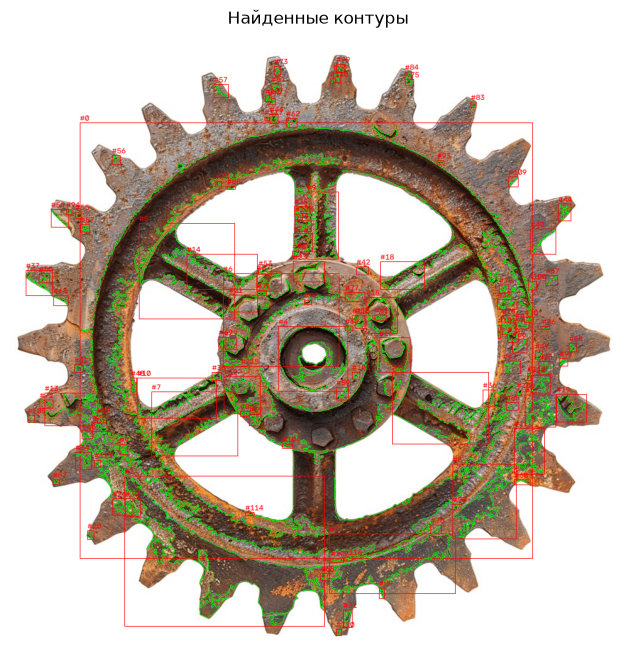

In [14]:
# Бинаризация с ИНВЕРСИЕЙ: дефект = белый, фон = чёрный
_, obj_mask = cv2.threshold(gray, 95, 255, cv2.THRESH_BINARY_INV)

# Показать маску
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(gray, cmap='gray'); axes[0].set_title('Серое'); axes[0].axis('off')
axes[1].imshow(obj_mask, cmap='gray'); axes[1].set_title('Маска (INV, порог=95)'); axes[1].axis('off')
plt.tight_layout()
plt.show()

# Поиск контуров
contours, _ = cv2.findContours(obj_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print(f'Найдено контуров всего: {len(contours)}')

# Фильтрация
contour_data = []
for c in contours:
    area = cv2.contourArea(c)
    if area < 20:  # мелкий шум — отбрасываем
        continue
    x, y, w_box, h_box = cv2.boundingRect(c)
    perimeter = cv2.arcLength(c, True)
    # отбрасываем контуры, касающиеся краёв
    if x < 3 or y < 3 or (x + w_box) > (w - 3) or (y + h_box) > (h - 3):
        continue
    contour_data.append((area, perimeter, (x, y, w_box, h_box), c))

contour_data.sort(reverse=True, key=lambda x: x[0])

print(f'\nОставлено контуров: {len(contour_data)}')
print(f'{"#":<5}{"Площадь":<12}{"BBox (x,y,w,h)"}')
print('-' * 45)
for i, (area, per, bbox, c) in enumerate(contour_data):
    print(f'{i:<5}{int(area):<12}{bbox}')

# Визуализация
img_vis = img.copy()
for i, (area, per, bbox, c) in enumerate(contour_data):
    x, y, w_box, h_box = bbox
    cv2.drawContours(img_vis, [c], -1, (0, 255, 0), 1)
    cv2.rectangle(img_vis, (x, y), (x + w_box, y + h_box), (0, 0, 255), 1)
    cv2.putText(img_vis, f'#{i}', (x, max(y-3, 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(img_vis, cv2.COLOR_BGR2RGB))
plt.title('Найденные контуры')
plt.axis('off')
plt.show()

**Шаг 5 - Обнаружение ключевых точек ORB**

Ключевых точек: 100


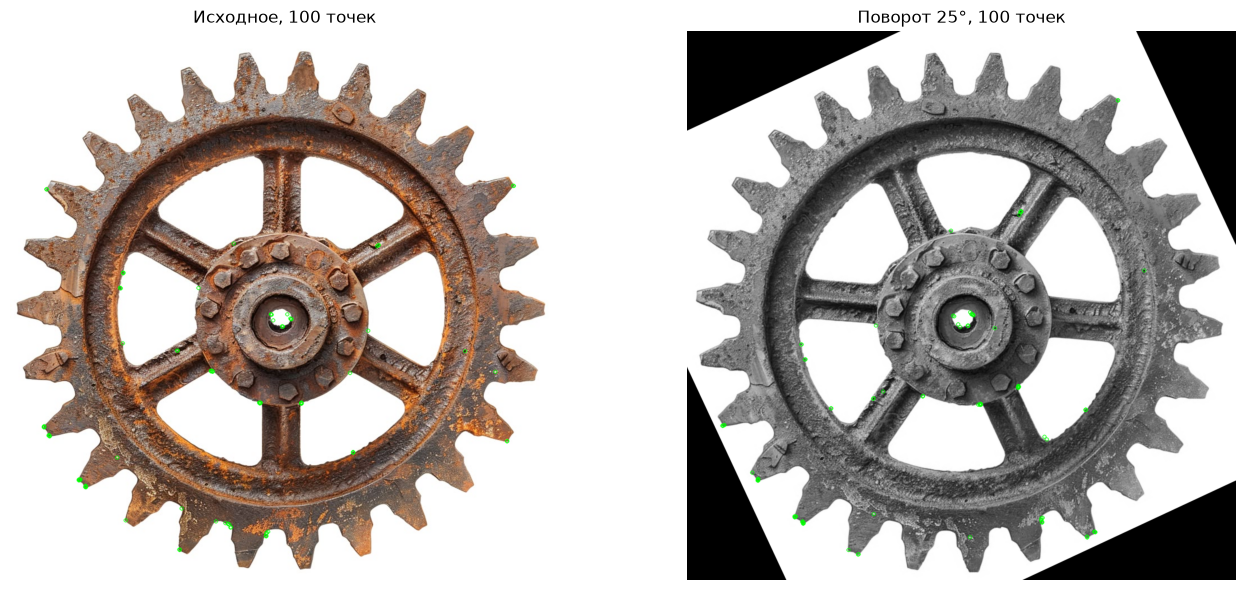

In [15]:
orb = cv2.ORB_create(nfeatures=100)
keypoints, descriptors = orb.detectAndCompute(gray, None)
print('Ключевых точек:', len(keypoints))

img_kp = cv2.drawKeypoints(img, keypoints, None, color=(0, 255, 0), flags=0)

# Поворот на 25°
M = cv2.getRotationMatrix2D((w//2, h//2), 25, 1.0)
rotated = cv2.warpAffine(gray, M, (w, h))
kp_rot, _ = orb.detectAndCompute(rotated, None)
img_kp_rot = cv2.drawKeypoints(cv2.cvtColor(rotated, cv2.COLOR_GRAY2BGR),
                                kp_rot, None, color=(0, 255, 0), flags=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(img_kp, cv2.COLOR_BGR2RGB))
axes[0].set_title(f'Исходное, {len(keypoints)} точек'); axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(img_kp_rot, cv2.COLOR_BGR2RGB))
axes[1].set_title(f'Поворот 25°, {len(kp_rot)} точек'); axes[1].axis('off')
plt.tight_layout()
plt.show()

**Шаг 6 - Текстовые и текстурные признаки**

ROI: (693, 720, 3)
Площадь: 104199
BBox: (111, 144, 720, 693)


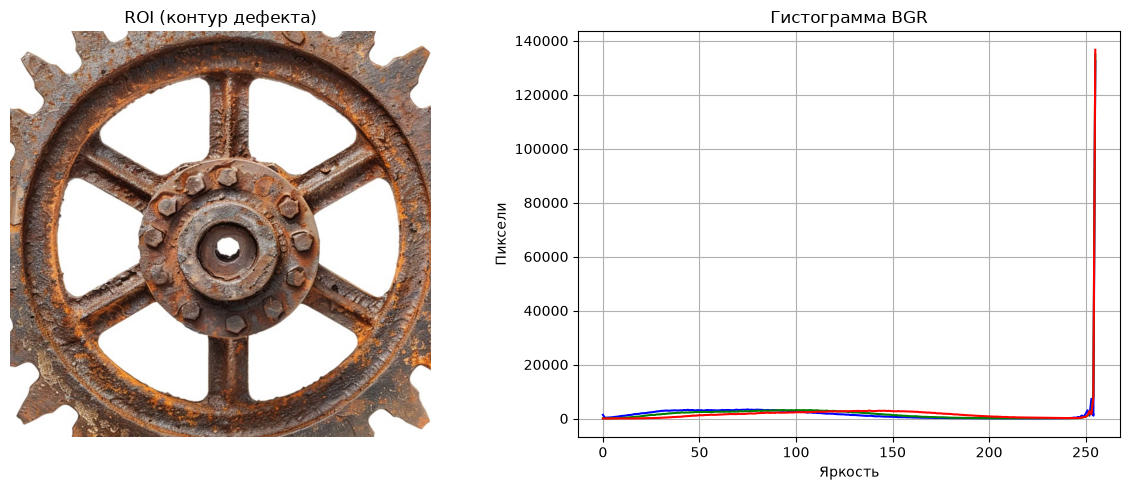

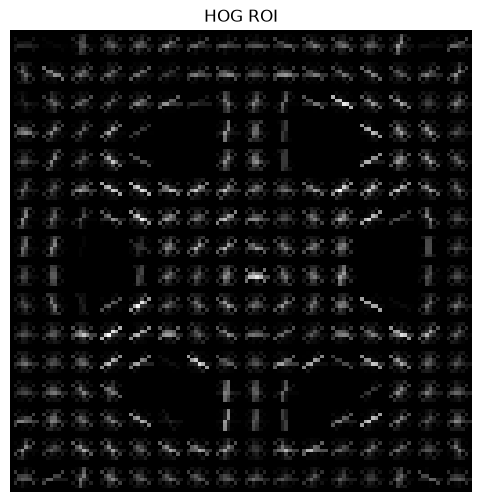

In [16]:
if not contour_data:
    raise RuntimeError('Нет контуров')

# Берём первый (самый большой) контур
area, per, bbox, selected_contour = contour_data[0]
x, y, w_box, h_box = bbox
roi = img[y:y+h_box, x:x+w_box]

print(f'ROI: {roi.shape}')
print(f'Площадь: {int(area)}')
print(f'BBox: {bbox}')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
axes[0].set_title('ROI (контур дефекта)'); axes[0].axis('off')

# Цветовая гистограмма
for i, color in enumerate(('b', 'g', 'r')):
    hist = cv2.calcHist([roi], [i], None, [256], [0, 256])
    axes[1].plot(hist, color=color)
axes[1].set_title('Гистограмма BGR')
axes[1].set_xlabel('Яркость')
axes[1].set_ylabel('Пиксели')
axes[1].grid(True)
plt.tight_layout()
plt.show()

# HOG
try:
    from skimage.feature import hog
except ImportError:
    # !pip install scikit-image -q
    from skimage.feature import hog

gray_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
gray_roi = cv2.resize(gray_roi, (128, 128))
_, hog_img = hog(gray_roi, orientations=9, pixels_per_cell=(8, 8),
                 cells_per_block=(2, 2), visualize=True)

plt.figure(figsize=(6, 6))
plt.imshow(hog_img, cmap='gray')
plt.title('HOG ROI')
plt.axis('off')
plt.show()

**Шаг 7 - Заливка**

Seed: (467, 482)


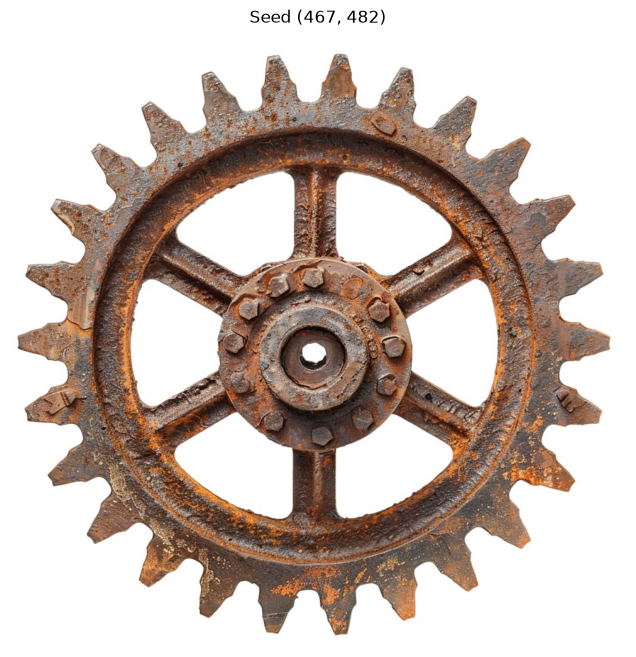

In [17]:
M = cv2.moments(selected_contour)
if M['m00'] > 0:
    cx = int(M['m10'] / M['m00'])
    cy = int(M['m01'] / M['m00'])
else:
    cx = x + w_box // 2
    cy = y + h_box // 2

seed_point = (cx, cy)
print('Seed:', seed_point)

img_seed = img.copy()
cv2.circle(img_seed, seed_point, 2, (0, 0, 255), -1)
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(img_seed, cv2.COLOR_BGR2RGB))
plt.title(f'Seed {seed_point}')
plt.axis('off')
plt.show()

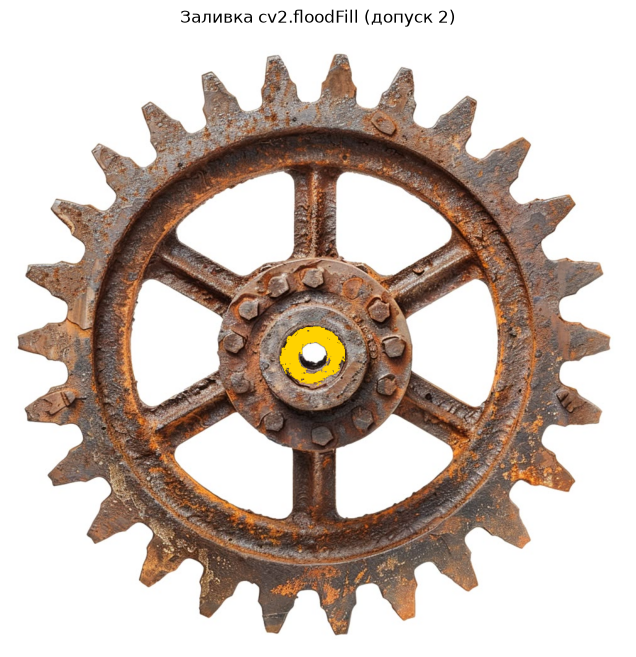

In [18]:
import numpy as np
img = cv2.imread(str(img_path))
img_flood = img.copy()
h_f, w_f = img_flood.shape[:2]
mask = np.zeros((h_f + 2, w_f + 2), np.uint8)

# Маленький допуск — чтобы не протечь на фон
lo_diff = (10, 10, 10)
up_diff = (10, 10, 10)

cv2.floodFill(img_flood, mask, seed_point, (0, 210, 255), lo_diff, up_diff)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(img_flood, cv2.COLOR_BGR2RGB))
plt.title('Заливка cv2.floodFill (допуск 2)')
plt.axis('off')
plt.show()

In [19]:
def check_left_neighbor(img_field, img, row, col):
    """Проверка ЛЕВОГО смежного пикселя."""
    if col - 1 < 0:
        return None
    color_cur = img[row, col]
    color_nb = img[row, col - 1]
    visited = img_field[row, col - 1] == 1
    same_color = tuple(color_cur) == tuple(color_nb)
    if same_color and not visited:
        img_field[row, col - 1] = 1
        return (row, col - 1)
    return None

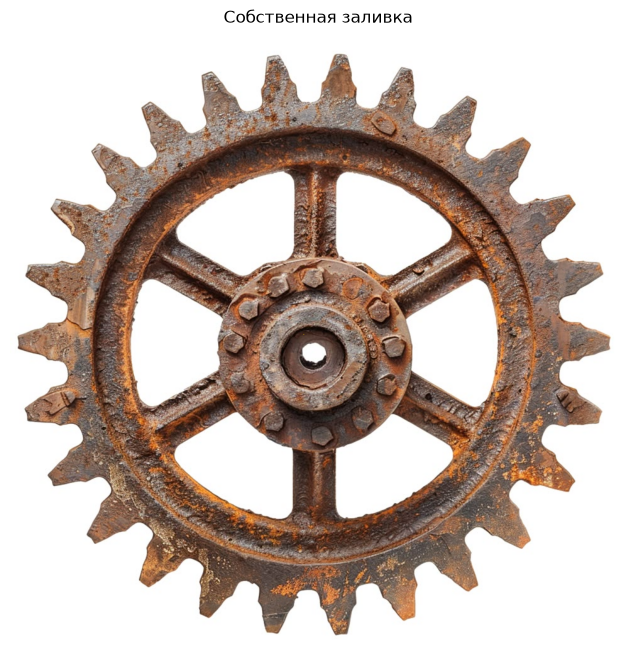

In [20]:
import numpy as np
def check_neighbor(img_field, img, row, col, direction):
    h_img, w_img = img.shape[:2]
    dr, dc = direction
    nr, nc = row + dr, col + dc
    if nr < 0 or nr >= h_img or nc < 0 or nc >= w_img:
        return None
    color_cur = img[row, col]
    color_nb = img[nr, nc]
    visited = img_field[nr, nc] == 1
    same_color = tuple(color_cur) == tuple(color_nb)
    if same_color and not visited:
        img_field[nr, nc] = 1
        return (nr, nc)
    return None


def manual_flood_fill(img, seed_point):
    h_img, w_img = img.shape[:2]
    img_field = np.zeros((h_img, w_img), dtype=np.uint8)
    result = img.copy()
    fill_color = (0, 210, 255)

    queue = [seed_point]
    img_field[seed_point[1], seed_point[0]] = 1
    result[seed_point[1], seed_point[0]] = fill_color

    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    while queue:
        row, col = queue.pop(0)
        for d in directions:
            nb = check_neighbor(img_field, img, row, col, d)
            if nb is not None:
                queue.append(nb)
                result[nb[0], nb[1]] = fill_color
    return result


img_manual = manual_flood_fill(img, seed_point)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(img_manual, cv2.COLOR_BGR2RGB))
plt.title('Собственная заливка')
plt.axis('off')
plt.show()

**Шаг - Сравнение с контуром**

In [21]:
mask_flood = cv2.inRange(img_flood, (0, 210, 255), (0, 210, 255))
area_flood = np.count_nonzero(mask_flood)
area_contour = int(contour_data[0][0])

print(f'Площадь контура: {area_contour}')
print(f'Площадь заливки: {area_flood}')
if area_contour > 0:
    print(f'Разница: {abs(area_flood - area_contour) / area_contour * 100:.1f}%')

Площадь контура: 104199
Площадь заливки: 5191
Разница: 95.0%


In [22]:
print('ПЕРЕЧЕНЬ ПРИЗНАКОВ ДЛЯ ЛР5')
print(f'1. Форма:')
print(f'   - площадь: {int(contour_data[0][0])}')
print(f'   - периметр: {int(contour_data[0][1])}')
print(f'   - bbox: {contour_data[0][2]}')
print(f'2. Ключевые точки ORB: {len(keypoints)}')
print(f'3. Цвет: гистограмма BGR (серая)')
print(f'4. Текстура: HOG')
print(f'5. Сегментация: заливка (проверка левого соседа)')

ПЕРЕЧЕНЬ ПРИЗНАКОВ ДЛЯ ЛР5
1. Форма:
   - площадь: 104199
   - периметр: 15547
   - bbox: (111, 144, 720, 693)
2. Ключевые точки ORB: 100
3. Цвет: гистограмма BGR (серая)
4. Текстура: HOG
5. Сегментация: заливка (проверка левого соседа)
